# UniMatch AI — Task 4: Data Preparation & Exploratory Data Analysis

This notebook implements Task 4 of the UniMatch AI project: loading, cleaning, merging, and exploring the admissions and ranking datasets, and producing the deliverables (Clean Dataset, EDA Report, Statistical Summary, Visualization Report, Data Quality Report).

**Datasets used:**
1. Graduate Admission Dataset (Mohan S. Acharya) — `Admission_Predict.csv` / `Admission_Predict_Ver1.1.csv`
2. University Recommendation Dataset (Nitisha Bharathi)
3. World University Rankings 2026 (QS + THE + ARWU combined) — used as the single ranking source, since it already includes QS, THE, and ARWU data (see note below on why QS 2025 was dropped)
4. College Admissions Dataset (Samson Qian) — used later for fairness auditing (Task 10)

> **Note:** an earlier draft also planned to use the standalone *QS World University Rankings 2025* dataset. We simplified to using only the combined 2026 dataset, since it already contains QS's ranking data alongside THE and ARWU — one ranking source instead of two, with no loss of QS coverage.

**Before running:** download the CSVs from the Kaggle links below and place them in `./data/`, or use the Kaggle API cell provided.

- https://www.kaggle.com/datasets/mohansacharya/graduate-admissions
- https://www.kaggle.com/datasets/nitishabharathi/university-recommendation
- https://www.kaggle.com/datasets/alitaqishah/world-university-rankings-2026-qs-and-the-and-arwu
- https://www.kaggle.com/datasets/samsonqian/college-admissions


In [ ]:
# 0. Setup
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

DATA_DIR = "./data"
OUT_DIR = "./outputs"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)


## 1. Dataset Loading & Merging

Load each raw dataset. Adjust filenames below to match what Kaggle actually gives you after unzipping (filenames occasionally vary by version).

In [ ]:
def safe_read_csv(path, **kwargs):
    """Read a CSV if it exists, otherwise warn and return an empty DataFrame."""
    if os.path.exists(path):
        df = pd.read_csv(path, low_memory=False, **kwargs)   # low_memory=False avoids the mixed-dtype warning
        print(f"Loaded {path} -> shape {df.shape}")
        return df
    else:
        print(f"WARNING: {path} not found. Place the file in {DATA_DIR}/ and re-run.")
        return pd.DataFrame()

# Graduate Admission dataset (try the v1.1 file first, fall back to v1)
df_admission = safe_read_csv(os.path.join(DATA_DIR, "Admission_Predict_Ver1.1.csv"))
if df_admission.empty:
    df_admission = safe_read_csv(os.path.join(DATA_DIR, "Admission_Predict.csv"))

# University Recommendation dataset
df_univ_rec = safe_read_csv(os.path.join(DATA_DIR, "university_recommendation.csv"))

# World University Rankings 2026 (QS+THE+ARWU combined) - single ranking source
df_wur_combined = safe_read_csv(os.path.join(DATA_DIR, "World_University_Rankings_2026.csv"))

# College Admissions dataset (for Task 10 fairness auditing, EDA'd here too)
df_college_admissions = safe_read_csv(os.path.join(DATA_DIR, "college_admissions.csv"))


Loaded ./data/Admission_Predict_Ver1.1.csv -> shape (500, 9)
Loaded ./data/university_recommendation.csv -> shape (53644, 26)
Loaded ./data/World_University_Rankings_2026.csv -> shape (57, 30)
Loaded ./data/college_admissions.csv -> shape (1534, 108)


In [ ]:
# Quick peek at each dataset
for name, df in [
    ("Graduate Admission", df_admission),
    ("University Recommendation", df_univ_rec),
    ("World Rankings 2026 Combined", df_wur_combined),
    ("College Admissions", df_college_admissions),
]:
    print("="*70)
    print(name, "-", df.shape)
    if not df.empty:
        display(df.head(3))
        print(df.dtypes)


Graduate Admission - (500, 9)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72


Serial No.             int64
GRE Score              int64
TOEFL Score            int64
University Rating      int64
SOP                  float64
LOR                  float64
CGPA                 float64
Research               int64
Chance of Admit      float64
dtype: object
University Recommendation - (53644, 26)


,userName,major,researchExp,industryExp,specialization,toeflScore,program,department,toeflEssay,internExp,greV,greQ,userProfileLink,journalPubs,greA,topperCgpa,termAndYear,confPubs,ugCollege,gmatA,cgpa,gmatQ,cgpaScale,gmatV,univName,admit
0,143saf,Systems and Control,0,18,Robotics,112.0,MS,Instrumentation & Control,26,5.0,160.0,167.0,http://www.edulix.com/unisearch/user.php?uid=2...,0,4.5,8.9,Fall - 2015,0,Dharamsinh Desai University,NaN,8.50,NaN,10,NaN,Worcester Polytechnic Institute,1
1,7790ashish,Manufacturing Engineering,0,0,NaN,NaN,MS,0,NaN,0.0,NaN,NaN,http://www.edulix.com/unisearch/user.php?uid=1...,0,NaN,0.0,Fall - 2013,0,NaN,NaN,0.00,NaN,0,NaN,Worcester Polytechnic Institute,1
2,AB25,(MIS / MSIM / MSIS / MSIT),0,66,NaN,94.0,MS,Computer Engineering,21,0.0,146.0,157.0,http://www.edulix.com/unisearch/user.php?uid=2...,0,3.0,81.0,Fall - 2015,0,IET DAVV,NaN,78.28,NaN,100,NaN,Worcester Polytechnic Institute,1


userName            object
major               object
researchExp          int64
industryExp          int64
specialization      object
toeflScore         float64
program             object
department          object
toeflEssay          object
internExp          float64
greV               float64
greQ               float64
userProfileLink     object
journalPubs         object
greA               float64
topperCgpa         float64
termAndYear         object
confPubs            object
ugCollege           object
gmatA              float64
cgpa               float64
gmatQ              float64
cgpaScale            int64
gmatV              float64
univName            object
admit                int64
dtype: object
World Rankings 2026 Combined - (57, 30)


,university,country,region,university_type,qs_rank_2026,the_rank_2026,arwu_rank_2025,qs_score,the_score,arwu_score,qs_academic_rep,qs_employer_rep,qs_faculty_student,qs_citations,qs_intl_faculty,qs_intl_students,the_teaching,the_research_env,the_research_quality,the_industry,the_intl_outlook,founded,total_students,intl_students_pct,nobel_laureates,fields_medalists,ranked_in_all_3,avg_rank_all3,university_age_2026,data_sources
0,MIT,USA,North America,Private,1.0,2.0,3.0,100.0,96.4,100.0,100.0,100.0,100.0,100.0,100.0,98.4,91.5,99.8,97.2,80.2,74.2,1861,11858,34,100,1,True,2.0,165,QS Jun-2025 | THE Oct-2025 | ARWU Aug-2025
1,Imperial College London,UK,Europe,Public,2.0,8.0,NaN,99.2,86.1,NaN,99.4,99.2,100.0,99.4,100.0,97.5,83.4,92.1,87.4,80.4,55.2,1907,19000,61,15,0,False,5.0,119,QS Jun-2025 | THE Oct-2025 | ARWU Aug-2025
2,Stanford University,USA,North America,Private,3.0,5.0,2.0,99.1,95.5,76.5,99.2,99.6,100.0,99.8,98.4,99.2,95.2,99.6,99.4,77.6,88.4,1885,17249,24,85,22,True,3.3,141,QS Jun-2025 | THE Oct-2025 | ARWU Aug-2025


university               object
country                  object
region                   object
university_type          object
qs_rank_2026            float64
the_rank_2026           float64
arwu_rank_2025          float64
qs_score                float64
the_score               float64
arwu_score              float64
qs_academic_rep         float64
qs_employer_rep         float64
qs_faculty_student      float64
qs_citations            float64
qs_intl_faculty         float64
qs_intl_students        float64
the_teaching            float64
the_research_env        float64
the_research_quality    float64
the_industry            float64
the_intl_outlook        float64
founded                   int64
total_students            int64
intl_students_pct         int64
nobel_laureates           int64
fields_medalists          int64
ranked_in_all_3            bool
avg_rank_all3           float64
university_age_2026       int64
data_sources             object
dtype: object
College Admissions - (1534

,Name,Applicants total,Admissions total,Enrolled total,Percent of freshmen submitting SAT scores,Percent of freshmen submitting ACT scores,SAT Critical Reading 25th percentile score,SAT Critical Reading 75th percentile score,SAT Math 25th percentile score,SAT Math 75th percentile score,SAT Writing 25th percentile score,SAT Writing 75th percentile score,ACT Composite 25th percentile score,ACT Composite 75th percentile score,"Estimated enrollment, total","Estimated enrollment, full time","Estimated enrollment, part time","Estimated undergraduate enrollment, total","Estimated undergraduate enrollment, full time","Estimated undergraduate enrollment, part time","Estimated freshman undergraduate enrollment, total","Estimated freshman enrollment, full time","Estimated freshman enrollment, part time","Estimated graduate enrollment, total","Estimated graduate enrollment, full time","Estimated graduate enrollment, part time",Number of students receiving an Associate's degree,Percent admitted - total,Admissions yield - total,"Tuition and fees, 2010-11","Tuition and fees, 2011-12","Tuition and fees, 2012-13","Tuition and fees, 2013-14",Total price for in-state students living on campus 2013-14,Total price for out-of-state students living on campus 2013-14,State abbreviation,FIPS state code,Geographic region,Sector of institution,Level of institution,Control of institution,Historically Black College or University,Tribal college,Degree of urbanization (Urban-centric locale),Carnegie Classification 2010: Basic,Total enrollment,Full-time enrollment,Part-time enrollment,Undergraduate enrollment,Graduate enrollment,...,Percent of total enrollment that are two or more races,Percent of total enrollment that are Race/ethnicity unknown,Percent of total enrollment that are Nonresident Alien,Percent of total enrollment that are Asian/Native Hawaiian/Pacific Islander,Percent of total enrollment that are women,Percent of undergraduate enrollment that are American Indian or Alaska Native,Percent of undergraduate enrollment that are Asian,Percent of undergraduate enrollment that are Black or African American,Percent of undergraduate enrollment that are Hispanic/Latino,Percent of undergraduate enrollment that are Native Hawaiian or Other Pacific Islander,Percent of undergraduate enrollment that are White,Percent of undergraduate enrollment that are two or more races,Percent of undergraduate enrollment that are Race/ethnicity unknown,Percent of undergraduate enrollment that are Nonresident Alien,Percent of undergraduate enrollment that are Asian/Native Hawaiian/Pacific Islander,Percent of undergraduate enrollment that are women,Percent of graduate enrollment that are American Indian or Alaska Native,Percent of graduate enrollment that are Asian,Percent of graduate enrollment that are Black or African American,Percent of graduate enrollment that are Hispanic/Latino,Percent of graduate enrollment that are Native Hawaiian or Other Pacific Islander,Percent of graduate enrollment that are White,Percent of graduate enrollment that are two or more races,Percent of graduate enrollment that are Race/ethnicity unknown,Percent of graduate enrollment that are Nonresident Alien,Percent of graduate enrollment that are Asian/Native Hawaiian/Pacific Islander,Percent of graduate enrollment that are women,Number of first-time undergraduates - in-state,Percent of first-time undergraduates - in-state,Number of first-time undergraduates - out-of-state,Percent of first-time undergraduates - out-of-state,Number of first-time undergraduates - foreign countries,Percent of first-time undergraduates - foreign countries,Number of first-time undergraduates - residence unknown,Percent of first-time undergraduates - residence unknown,"Graduation rate - Bachelor degree within 4 years, total","Graduation rate - Bachelor degree within 5 years, total","Graduation rate - Bachelor degree within 6 years, total",Percent of freshmen receiving any financial aid,"Percent of freshmen receiving fede

Name                                                      object
Applicants total                                         float64
Admissions total                                         float64
Enrolled total                                           float64
Percent of freshmen submitting SAT scores                float64
                                                          ...   
Percent of freshmen receiving student loan aid           float64
Percent of freshmen receiving federal student loans      float64
Percent of freshmen receiving other loan aid             float64
Endowment assets (year end) per FTE enrollment (GASB)    float64
Endowment assets (year end) per FTE enrollment (FASB)    float64
Length: 108, dtype: object


In [ ]:
# Standardize column names across all datasets (lowercase, no spaces)
def clean_columns(df):
    if df.empty:
        return df
    df = df.copy()
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
        .str.replace(".", "", regex=False)
        .str.replace("(", "", regex=False)
        .str.replace(")", "", regex=False)
    )
    return df

df_admission      = clean_columns(df_admission)
df_univ_rec       = clean_columns(df_univ_rec)
df_wur_combined   = clean_columns(df_wur_combined)
df_college_admissions = clean_columns(df_college_admissions)

print(df_admission.columns.tolist() if not df_admission.empty else "df_admission empty")


['serial_no', 'gre_score', 'toefl_score', 'university_rating', 'sop', 'lor', 'cgpa', 'research', 'chance_of_admit']


### Merging strategy

- `df_admission` is applicant-level (GRE, TOEFL, University Rating, SOP, LOR, CGPA, Research, Chance of Admit) and has **no explicit university name** — it's used standalone for Tasks 4-7 (ML/DL admission-chance modeling), keyed by an internal `serial_no`.
- `df_univ_rec` (applicant → university records) is merged with `df_wur_combined` (rankings) on university name to build the knowledge base and search space (Tasks 1 & 3).
- An `is_ranked` flag marks rows that matched a real ranked university. Ranking columns for unmatched rows are left **empty (NaN)** — they are *not* filled with a fake median rank.


In [ ]:
def find_university_col(df):
    candidates = [c for c in df.columns if "univ" in c or "institution" in c or "name" in c]
    return candidates

print("University Recommendation candidate cols:", find_university_col(df_univ_rec))
print("World Rankings 2026 candidate cols:", find_university_col(df_wur_combined))


University Recommendation candidate cols: ['username', 'univname']
World Rankings 2026 candidate cols: ['university', 'university_type', 'university_age_2026']


In [ ]:
# University name matching: normalise names + small alias table, then EXACT match.
# Plain exact matching missed names spelled differently in the two files
# (e.g. "Massachusetts Institute of Technology" vs "MIT"). Fuzzy matching was tried but
# produced WRONG matches (University of Florida -> University of Oxford, Purdue -> Duke,
# Syracuse -> Yale), so it is not used; the alias table handles the real differences.
import re

UNIV_COL_REC = "univname"
UNIV_COL_WUR = "university"

# Common long-name -> short-name aliases. Extend this after checking the "unmatched" list printed below.
ALIASES = {
    "massachusetts institute of technology": "mit",
    "california institute of technology": "caltech",
    "university of california los angeles": "ucla",
    "university of michigan ann arbor": "univ of michigan",
    "university of pennsylvania": "univ of pennsylvania",
    "new york university": "nyu",
}

def normalize_name(s):
    if pd.isna(s):
        return None
    s = str(s).lower().strip()
    s = re.sub(r"[^a-z0-9 ]", " ", s)        # drop punctuation (commas, hyphens, brackets)
    s = re.sub(r"\s+", " ", s).strip()
    s = re.sub(r"^the ", "", s)
    return ALIASES.get(s, s)

df_wur_combined["univ_key"] = df_wur_combined[UNIV_COL_WUR].map(normalize_name)
canonical_keys = df_wur_combined["univ_key"].dropna().unique().tolist()

def match_key(name):
    key = normalize_name(name)
    return key if key in canonical_keys else None

# Match only the unique university names (fast), then map back onto every row
unique_names = df_univ_rec[UNIV_COL_REC].dropna().unique()
name_to_key = {n: match_key(n) for n in unique_names}
df_univ_rec["univ_key"] = df_univ_rec[UNIV_COL_REC].map(name_to_key)

matched_rows = df_univ_rec["univ_key"].notna().sum()
matched_unique = sum(1 for v in name_to_key.values() if v is not None)
print(f"Match rate: {matched_rows}/{len(df_univ_rec)} rows ({matched_rows/len(df_univ_rec)*100:.1f}%) "
      f"across {matched_unique}/{len(unique_names)} unique university names.")
print("Matched:", sorted(n for n, k in name_to_key.items() if k is not None))
print("Unmatched names (add to ALIASES if they are in the rankings file):")
print(sorted(n for n, k in name_to_key.items() if k is None))

df_university_master = df_univ_rec.merge(df_wur_combined, on="univ_key", how="left", suffixes=("", "_wur"))
df_university_master["is_ranked"] = df_university_master["univ_key"].notna().astype(int)
print("df_university_master shape:", df_university_master.shape)


Match rate: 5695/53644 rows (10.6%) across 13/54 unique university names.
Matched: ['California Institute of Technology', 'Carnegie Mellon University', 'Columbia University', 'Cornell University', 'Harvard University', 'Johns Hopkins University', 'Massachusetts Institute of Technology', 'New York University', 'Princeton University', 'Stanford University', 'University of California Los Angeles', 'University of Michigan Ann Arbor', 'University of Pennsylvania']
Unmatched names (add to ALIASES if they are in the rankings file):
['Arizona State University', 'Clemson University', 'George Mason University', 'Georgia Institute of Technology', 'New Jersey Institute of Technology', 'North Carolina State University', 'Northeastern University', 'Northwestern University', 'Ohio State University Columbus', 'Purdue University', 'Rutgers University New Brunswick/Piscataway', 'SUNY Buffalo', 'SUNY Stony Brook', 'Syracuse University', 'Texas A and M University College Station', 'University of Arizona',

## 2. Data Understanding

In [ ]:
def profile(df, name):
    print("="*70)
    print(f"PROFILE: {name}")
    print("Shape:", df.shape)
    print("\nDtypes:\n", df.dtypes)
    print("\nMissing values (count / %):")
    miss = df.isna().sum()
    pct = (miss / len(df) * 100).round(2) if len(df) else miss
    print(pd.DataFrame({"missing": miss, "pct": pct}).query("missing > 0"))
    print("\nDuplicate rows:", df.duplicated().sum())

for name, df in [
    ("Graduate Admission", df_admission),
    ("University Master (merged)", df_university_master),
    ("College Admissions", df_college_admissions),
]:
    if not df.empty:
        profile(df, name)


PROFILE: Graduate Admission
Shape: (500, 9)

Dtypes:
 serial_no              int64
gre_score              int64
toefl_score            int64
university_rating      int64
sop                  float64
lor                  float64
cgpa                 float64
research               int64
chance_of_admit      float64
dtype: object

Missing values (count / %):
Empty DataFrame
Columns: [missing, pct]
Index: []

Duplicate rows: 0
PROFILE: University Master (merged)
Shape: (53644, 58)

Dtypes:
 username                 object
major                    object
researchexp               int64
industryexp               int64
specialization           object
toeflscore              float64
program                  object
department               object
toeflessay               object
internexp               float64
grev                    float64
greq                    float64
userprofilelink          object
journalpubs              object
grea                    float64
toppercgpa              floa

## 3. Duplicate Removal & Invalid-Value Cleaning

Done **before** imputation, so duplicates and impossible values don't distort the medians/modes used to fill gaps.

The University Recommendation data mixes the **old GRE scale (200-800)** with the **new scale (130-170)**, and contains typos (e.g. GRE 7990, TOEFL 1350, zeros). Old-scale GRE scores are converted to the new scale with an approximate linear mapping; impossible values are set to NaN and imputed in the next step.


In [ ]:
def drop_duplicates_report(df, name):
    if df.empty:
        return df
    before = len(df)
    df = df.drop_duplicates()
    print(f"{name}: removed {before - len(df)} duplicate rows ({before} -> {len(df)})")
    return df

def gre_to_new_scale(s):
    """New scale (130-170) kept; old scale (200-800) mapped linearly to 130-170; anything else -> NaN."""
    s = pd.to_numeric(s, errors="coerce")
    new = s.where(s.between(130, 170))
    old = s.where(s.between(200, 800))
    return new.fillna(130 + (old - 200) * 40 / 600).round()

def fix_invalid_values(df):
    df = df.copy()
    before_na = df.isna().sum().sum()
    for c in ["grev", "greq"]:
        df[c] = gre_to_new_scale(df[c])
    df["grea"] = pd.to_numeric(df["grea"], errors="coerce").where(lambda s: s.between(0.5, 6))
    df["toeflscore"] = pd.to_numeric(df["toeflscore"], errors="coerce").where(lambda s: s.between(40, 120))
    # CGPA is only meaningful with a valid scale and cgpa <= scale
    valid_cgpa = (df["cgpascale"] > 0) & (df["cgpa"] > 0) & (df["cgpa"] <= df["cgpascale"])
    df.loc[~valid_cgpa, ["cgpa", "cgpascale"]] = np.nan
    # Mixed-type text/number columns -> numeric
    for c in ["journalpubs", "confpubs", "toeflessay"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    print(f"Invalid values set to NaN: {df.isna().sum().sum() - before_na}")
    return df

df_admission_clean = drop_duplicates_report(df_admission, "Graduate Admission")
df_university_clean = drop_duplicates_report(df_university_master, "University Master")
df_university_clean = fix_invalid_values(df_university_clean)
df_university_clean[["grev", "greq", "grea", "toeflscore", "cgpa"]].describe().T


Graduate Admission: removed 0 duplicate rows (500 -> 500)
University Master: removed 117 duplicate rows (53644 -> 53527)
Invalid values set to NaN: 7720


,count,mean,std,min,25%,50%,75%,max
grev,51680.0,153.260372,6.034474,132.0,149.00,153.0,157.0,170.0
greq,51627.0,164.871831,4.706504,136.0,162.00,166.0,169.0,170.0
grea,50533.0,3.622906,0.591856,1.5,3.00,3.5,4.0,6.0
toeflscore,47605.0,105.280685,7.745440,57.0,101.00,106.0,111.0,120.0
cgpa,51156.0,41.052813,32.140036,1.0,8.32,58.0,72.0,100.0


## 4. Missing Value Handling

In [ ]:
def handle_missing(df, numeric_strategy="median", drop_thresh=0.6, skip_cols=None):
    """
    - Drop columns missing more than `drop_thresh` of values (except `skip_cols`).
    - Impute numeric columns with median, categorical columns with mode.
    - `skip_cols` are neither dropped nor imputed. Used for ranking columns: they only exist
      for applicants who applied to one of the 57 ranked universities, so for every other row
      "missing" genuinely means "not ranked" - filling them with a median rank would invent data.
    """
    if df.empty:
        return df
    df = df.copy()
    skip_cols = set(skip_cols or [])

    missing_frac = df.isna().mean()
    cols_to_drop = [c for c in missing_frac[missing_frac > drop_thresh].index if c not in skip_cols]
    if cols_to_drop:
        print("Dropping high-missingness columns:", cols_to_drop)
    df = df.drop(columns=cols_to_drop)

    for c in df.columns:
        if c in skip_cols or not df[c].isna().any() or df[c].notna().sum() == 0:
            continue
        if pd.api.types.is_numeric_dtype(df[c]):
            fill_val = df[c].median() if numeric_strategy == "median" else df[c].mean()
        else:
            fill_val = df[c].mode(dropna=True).iloc[0]
        df[c] = df[c].fillna(fill_val)
    return df

# Every column that came from the rankings file (plus the join key) is left as-is
RANKING_COLS = [c for c in df_university_clean.columns if c not in df_univ_rec.columns] + ["univ_key"]
print("Ranking columns left un-imputed (NaN = not ranked):", RANKING_COLS)

df_admission_clean = handle_missing(df_admission_clean)
df_university_clean = handle_missing(df_university_clean, skip_cols=RANKING_COLS)
print("Remaining NaNs outside ranking columns:",
      int(df_university_clean.drop(columns=RANKING_COLS, errors="ignore").isna().sum().sum()))


Ranking columns left un-imputed (NaN = not ranked): ['university', 'country', 'region', 'university_type', 'qs_rank_2026', 'the_rank_2026', 'arwu_rank_2025', 'qs_score', 'the_score', 'arwu_score', 'qs_academic_rep', 'qs_employer_rep', 'qs_faculty_student', 'qs_citations', 'qs_intl_faculty', 'qs_intl_students', 'the_teaching', 'the_research_env', 'the_research_quality', 'the_industry', 'the_intl_outlook', 'founded', 'total_students', 'intl_students_pct', 'nobel_laureates', 'fields_medalists', 'ranked_in_all_3', 'avg_rank_all3', 'university_age_2026', 'data_sources', 'is_ranked', 'univ_key']
Dropping high-missingness columns: ['toeflessay', 'gmata', 'gmatq', 'gmatv']
Remaining NaNs outside ranking columns: 0


## 5. Outlier Detection (IQR method)

In [ ]:
def detect_outliers_iqr(df, cols, factor=1.5):
    """Return a dict of {col: outlier_count} and a boolean mask of outlier rows (any column)."""
    outlier_counts = {}
    mask_any = pd.Series(False, index=df.index)
    for c in cols:
        q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
        iqr = q3 - q1
        mask = (df[c] < q1 - factor * iqr) | (df[c] > q3 + factor * iqr)
        outlier_counts[c] = int(mask.sum())
        mask_any = mask_any | mask
    return outlier_counts, mask_any

if not df_admission_clean.empty:
    # Exclude the ID, the binary 'research' flag and the TARGET - the target must never be modified
    num_cols = [c for c in df_admission_clean.select_dtypes(include=[np.number]).columns
                if c not in ("serial_no", "research", "chance_of_admit")]
    counts, mask_any = detect_outliers_iqr(df_admission_clean, num_cols)
    print("Outlier counts per column (Graduate Admission):", counts)
    print("Rows flagged as outliers in at least one column:", mask_any.sum())
    # Decision: cap (winsorize) predictors rather than drop rows, to avoid losing data
    for c in num_cols:
        q1, q3 = df_admission_clean[c].quantile(0.25), df_admission_clean[c].quantile(0.75)
        iqr = q3 - q1
        df_admission_clean[c] = df_admission_clean[c].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    print("Predictor outliers capped (winsorized) using IQR bounds. Target left unchanged.")


Outlier counts per column (Graduate Admission): {'gre_score': 0, 'toefl_score': 0, 'university_rating': 0, 'sop': 0, 'lor': 1, 'cgpa': 0}
Rows flagged as outliers in at least one column: 1
Predictor outliers capped (winsorized) using IQR bounds. Target left unchanged.


## 6. Encoding & Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

df_admission_encoded = df_admission_clean.copy()

# Research is already binary (0/1) in the Graduate Admission dataset - no encoding needed
# If a 'university_rating' or categorical program/country column exists, label/one-hot encode it here:
categorical_cols = df_admission_encoded.select_dtypes(exclude=[np.number]).columns.tolist()
print("Categorical columns to encode:", categorical_cols)

for c in categorical_cols:
    le = LabelEncoder()
    df_admission_encoded[c] = le.fit_transform(df_admission_encoded[c].astype(str))

# Scale numeric predictor columns (exclude target 'chance_of_admit' and id column)
target_col_candidates = [c for c in df_admission_encoded.columns if "chance" in c]
target_col = target_col_candidates[0] if target_col_candidates else None
id_cols = [c for c in df_admission_encoded.columns if "serial" in c]

feature_cols = [c for c in df_admission_encoded.columns if c not in id_cols + ([target_col] if target_col else [])]

# NOTE: this scaled copy is for EDA/illustration only. For modelling, the scaler must be fit
# on the TRAINING split only (done in Task 6) - fitting it on all 500 rows here leaks test data.
scaler = StandardScaler()
df_admission_scaled = df_admission_encoded.copy()
df_admission_scaled[feature_cols] = scaler.fit_transform(df_admission_encoded[feature_cols])

print("Target column detected:", target_col)
print("Features scaled:", feature_cols)
df_admission_scaled.head()


Categorical columns to encode: []
Target column detected: chance_of_admit
Features scaled: ['gre_score', 'toefl_score', 'university_rating', 'sop', 'lor', 'cgpa', 'research']


,serial_no,gre_score,toefl_score,university_rating,sop,lor,cgpa,research,chance_of_admit
0,1,1.819238,1.778865,0.775582,1.137360,1.100744,1.776806,0.886405,0.92
1,2,0.667148,-0.031601,0.775582,0.632315,1.100744,0.485859,0.886405,0.76
2,3,-0.041830,-0.525364,-0.099793,-0.377773,0.016267,-0.954043,0.886405,0.72
3,4,0.489904,0.462163,-0.099793,0.127271,-1.068210,0.154847,0.886405,0.80
4,5,-0.219074,-0.689952,-0.975168,-1.387862,-0.525971,-0.606480,-1.128152,0.65


## 7. Exploratory Data Analysis (EDA) & Visualization

In [ ]:
# 7.1 Statistical summary
if not df_admission_clean.empty:
    display(df_admission_clean.describe().T)


,count,mean,std,min,25%,50%,75%,max
serial_no,500.0,250.50000,144.481833,1.00,125.7500,250.50,375.25,500.00
gre_score,500.0,316.47200,11.295148,290.00,308.0000,317.00,325.00,340.00
toefl_score,500.0,107.19200,6.081868,92.00,103.0000,107.00,112.00,120.00
university_rating,500.0,3.11400,1.143512,1.00,2.0000,3.00,4.00,5.00
sop,500.0,3.37400,0.991004,1.00,2.5000,3.50,4.00,5.00
lor,500.0,3.48500,0.923027,1.50,3.0000,3.50,4.00,5.00
cgpa,500.0,8.57644,0.604813,6.80,8.1275,8.56,9.04,9.92
research,500.0,0.56000,0.496884,0.00,0.0000,1.00,1.00,1.00
chance_of_admit,500.0,0.72174,0.141140,0.34,0.6300,0.72,0.82,0.97


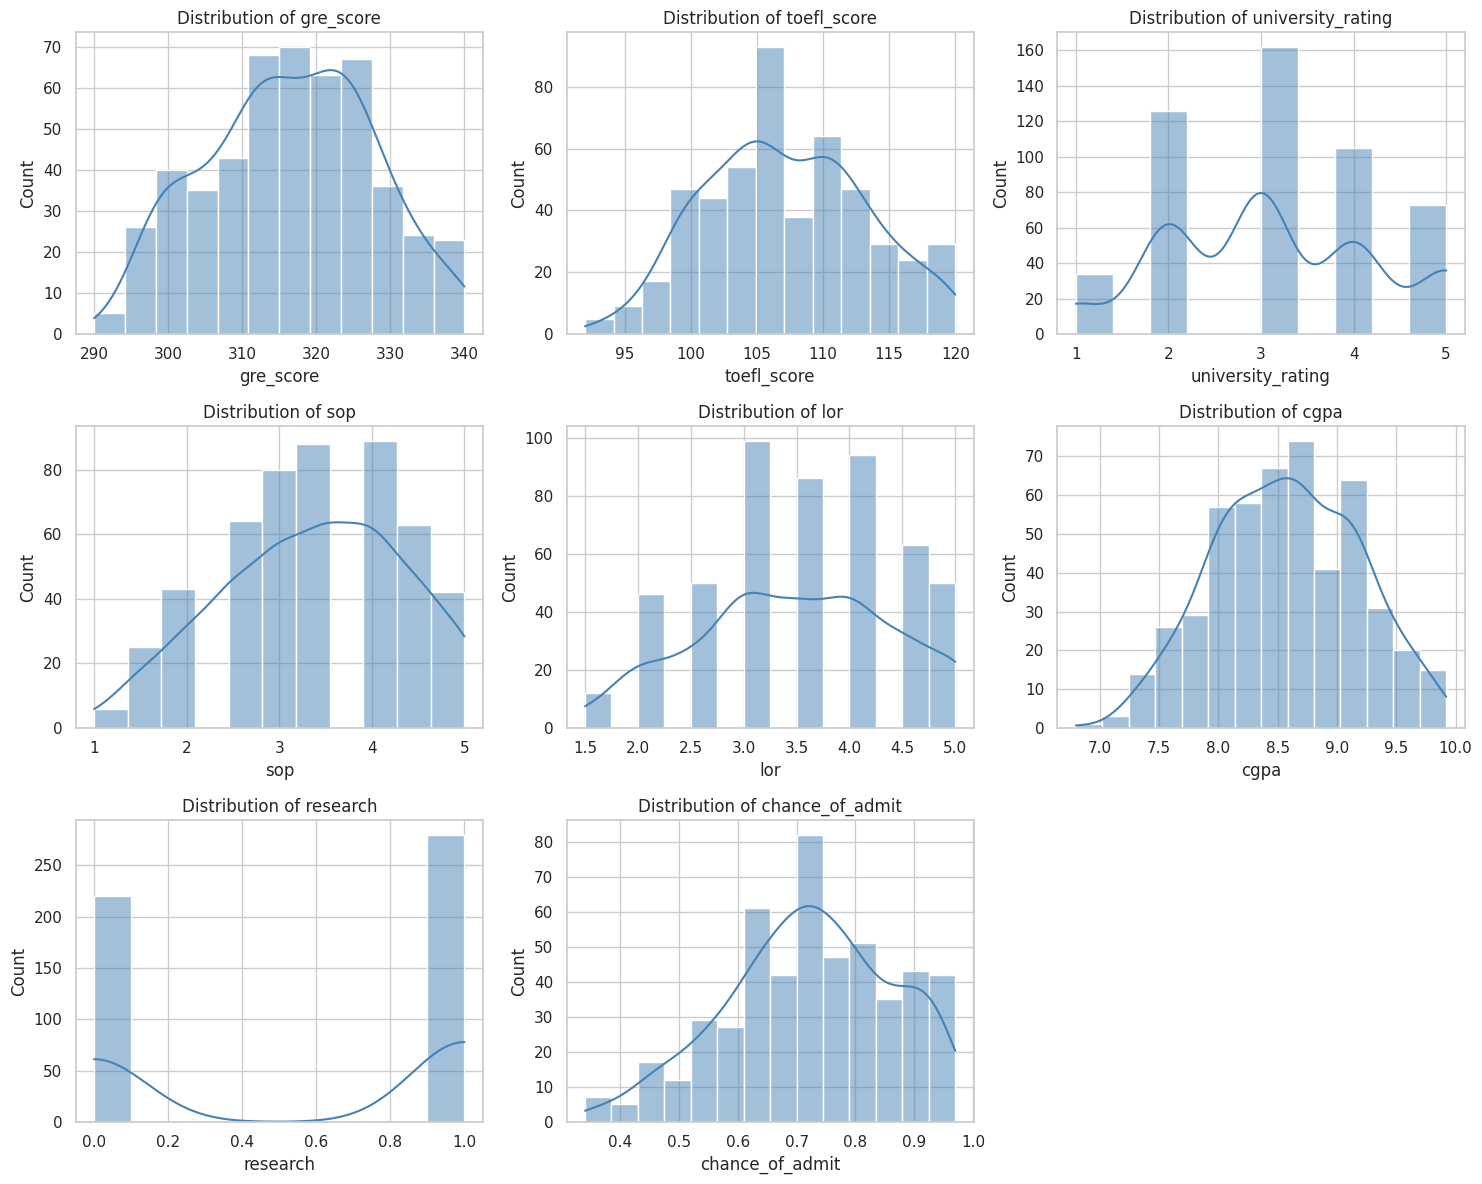

In [ ]:
# 7.2 Distribution of key numeric features
if not df_admission_clean.empty:
    num_cols_plot = [c for c in df_admission_clean.select_dtypes(include=[np.number]).columns if "serial" not in c]
    n = len(num_cols_plot)
    ncols = 3
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4*nrows))
    axes = np.array(axes).reshape(-1)
    for ax, c in zip(axes, num_cols_plot):
        sns.histplot(df_admission_clean[c], kde=True, ax=ax, color="steelblue")
        ax.set_title(f"Distribution of {c}")
    for ax in axes[len(num_cols_plot):]:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "distributions.png"), dpi=150)
    plt.show()


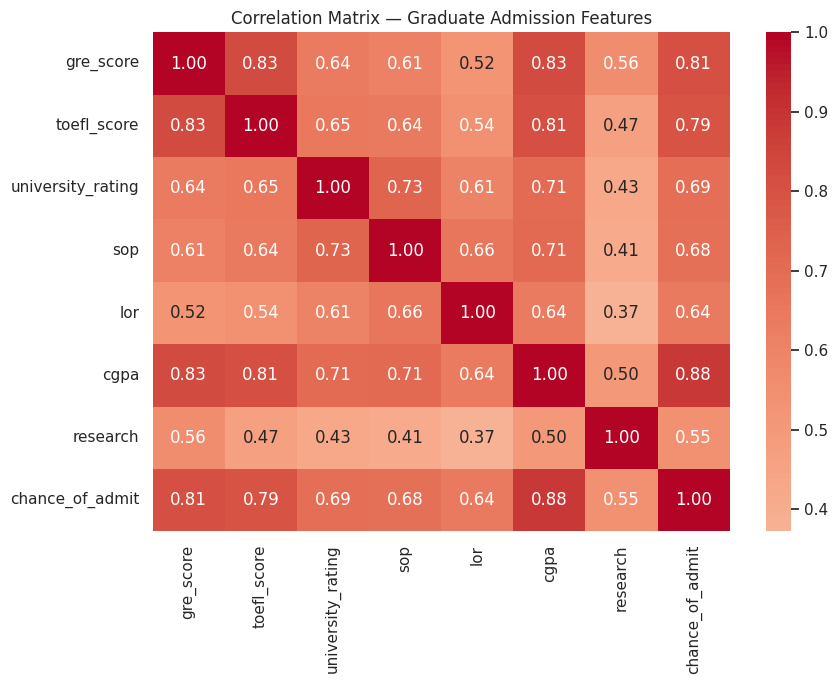

In [ ]:
# 7.3 Correlation heatmap
if not df_admission_clean.empty:
    num_cols_corr = [c for c in df_admission_clean.select_dtypes(include=[np.number]).columns if "serial" not in c]
    plt.figure(figsize=(9, 7))
    corr = df_admission_clean[num_cols_corr].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Matrix — Graduate Admission Features")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "correlation_matrix.png"), dpi=150)
    plt.show()


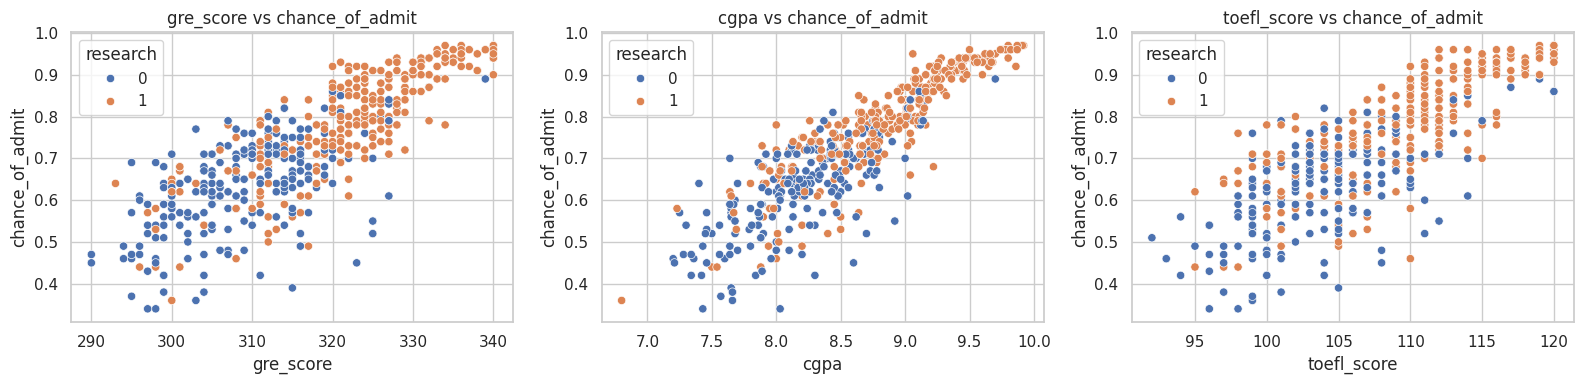

In [ ]:
# 7.4 Relationship between key predictors and Chance of Admit
if not df_admission_clean.empty and target_col:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    predictor_candidates = [c for c in ["gre_score", "cgpa", "toefl_score"] if c in df_admission_clean.columns]
    for ax, c in zip(axes, predictor_candidates):
        sns.scatterplot(data=df_admission_clean, x=c, y=target_col, hue="research" if "research" in df_admission_clean.columns else None, ax=ax)
        ax.set_title(f"{c} vs {target_col}")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "predictors_vs_target.png"), dpi=150)
    plt.show()


Ranked universities present in applicant data: 13
Applicant rows with a real ranking: 5695 (10.6%)


,univname,university,qs_rank_2026,the_rank_2026,arwu_rank_2025,avg_rank_all3
10851,University of Pennsylvania,Univ of Pennsylvania,12.0,14.0,NaN,13.0
14129,University of Michigan Ann Arbor,Univ of Michigan,23.0,22.0,21.0,22.0
24908,University of California Los Angeles,UCLA,40.0,22.0,NaN,31.0
35054,Stanford University,Stanford University,3.0,5.0,2.0,3.3
36982,Princeton University,Princeton University,15.0,3.0,7.0,8.3
43483,New York University,NYU,38.0,27.0,NaN,32.5
44477,Massachusetts Institute of Technology,MIT,1.0,2.0,3.0,2.0
44577,Johns Hopkins University,Johns Hopkins University,24.0,21.0,NaN,22.5
44764,Harvard University,Harvard University,5.0,5.0,1.0,3.7
47180,Cornell University,Cornell University,13.0,18.0,NaN,15.5


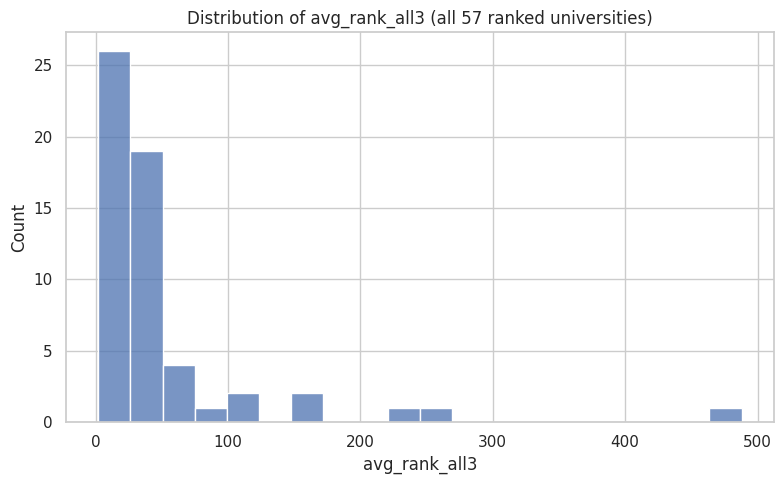

In [ ]:
# 7.5 University ranking distribution - only real (matched) universities, one point per university
ranked_unis = (df_university_clean[df_university_clean["is_ranked"] == 1]
               .drop_duplicates("univ_key"))
print(f"Ranked universities present in applicant data: {len(ranked_unis)}")
print(f"Applicant rows with a real ranking: {df_university_clean['is_ranked'].sum()} "
      f"({df_university_clean['is_ranked'].mean()*100:.1f}%)")
if len(ranked_unis):
    display(ranked_unis[["univname", "university", "qs_rank_2026", "the_rank_2026", "arwu_rank_2025", "avg_rank_all3"]])

plt.figure(figsize=(8, 5))
sns.histplot(df_wur_combined["avg_rank_all3"].dropna(), bins=20)
plt.title("Distribution of avg_rank_all3 (all 57 ranked universities)")
plt.xlabel("avg_rank_all3")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "ranking_distribution.png"), dpi=150)
plt.show()


## 8. Data Quality Assessment

In [ ]:
def data_quality_report(df, name):
    if df.empty:
        return {"dataset": name, "status": "NOT LOADED"}
    report = {
        "dataset": name,
        "rows": len(df),
        "columns": df.shape[1],
        "duplicate_rows_remaining": int(df.duplicated().sum()),
        "missing_values_remaining": int(df.isna().sum().sum()),
        "missing_pct_remaining": round(df.isna().sum().sum() / df.size * 100, 3) if df.size else 0,
        "numeric_columns": df.select_dtypes(include=[np.number]).shape[1],
        "categorical_columns": df.select_dtypes(exclude=[np.number]).shape[1],
    }
    if "is_ranked" in df.columns:
        report["rows_with_real_ranking"] = int(df["is_ranked"].sum())
    return report

reports = [
    data_quality_report(df_admission_clean, "Graduate Admission (clean)"),
    data_quality_report(df_university_clean, "University Master (clean)"),
    data_quality_report(df_college_admissions, "College Admissions (raw)"),
]
df_quality_report = pd.DataFrame(reports)
display(df_quality_report)
df_quality_report.to_csv(os.path.join(OUT_DIR, "data_quality_report.csv"), index=False)


,dataset,rows,columns,duplicate_rows_remaining,missing_values_remaining,missing_pct_remaining,numeric_columns,categorical_columns,rows_with_real_ranking
0,Graduate Admission (clean),500,9,0,0,0.000,9,0,NaN
1,University Master (clean),53527,54,0,1490804,51.577,38,16,5695.0
2,College Admissions (raw),1534,108,0,16275,9.824,97,11,NaN


## 9. Save Deliverables

Saves the clean dataset(s), the data quality report, and the visualizations already written to `./outputs/` above.

In [ ]:
# Save clean datasets (Task 4 core deliverable)
if not df_admission_clean.empty:
    df_admission_clean.to_csv(os.path.join(OUT_DIR, "graduate_admission_clean.csv"), index=False)
    df_admission_scaled.to_csv(os.path.join(OUT_DIR, "graduate_admission_clean_scaled.csv"), index=False)

if not df_university_clean.empty:
    df_university_clean.to_csv(os.path.join(OUT_DIR, "university_master_clean.csv"), index=False)

print("Saved deliverables to", OUT_DIR)
print(os.listdir(OUT_DIR))


Saved deliverables to ./outputs
['correlation_matrix.png', 'predictors_vs_target.png', 'university_master_clean.csv', 'ranking_distribution.png', 'graduate_admission_clean_scaled.csv', 'distributions.png', 'graduate_admission_clean.csv', 'data_quality_report.csv']


## Task 4 Deliverables Checklist

- [x] **Clean Dataset** — `outputs/graduate_admission_clean.csv`, `outputs/university_master_clean.csv`
- [x] **EDA Report** — histograms, correlation heatmap, scatter plots (sections 7.1-7.5)
- [x] **Statistical Summary** — `df_admission_clean.describe()` output (section 7.1)
- [x] **Visualization Report** — PNGs saved in `outputs/`
- [x] **Data Quality Report** — `outputs/data_quality_report.csv`

**Next step (Task 5):** use `graduate_admission_clean.csv` (unscaled — scaling is done in Task 6 on the training split) and `university_master_clean.csv` to engineer Fit Score, Affordability Index, Admit-Chance Index and Rank-Tier features.
